<a href="https://colab.research.google.com/github/ralph-Jung/AI-Class/blob/main/6%EC%A3%BC%EC%B0%A8/10_12_mnist_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

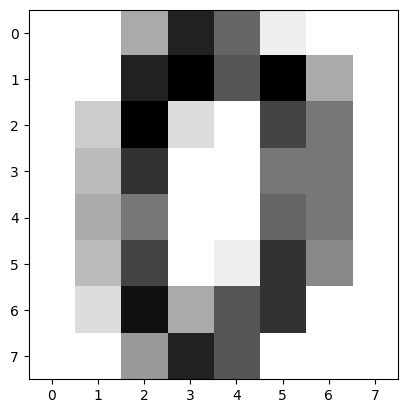

In [5]:
# Mnist 분류
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import tensorflow as tf
import pandas as pd


# 8x8 손글씨 숫자 이미지 데이터 불러오기
digits = datasets.load_digits()
plt.imshow(digits.images[0], cmap=plt.cm.gray_r, interpolation='nearest')
plt.show()

# 8x8 이미지를 64개 값이 한 줄로 늘어선 형태로 펼치기
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))


In [2]:
# 3. 데이터 구조 확인
print("이미지 배열 크기:", digits.images.shape)   # (1797, 8, 8)
print("펼친 데이터 크기:", data.shape)            # (1797, 64)
print("라벨 크기:", digits.target.shape)
print("픽셀 값 범위:", data.min(), "~", data.max())  # 0 ~ 16
print("결측치 개수:", np.isnan(data).sum())

print("\n클래스별 개수")
print(pd.Series(digits.target).value_counts().sort_index())

이미지 배열 크기: (1797, 8, 8)
펼친 데이터 크기: (1797, 64)
라벨 크기: (1797,)
픽셀 값 범위: 0.0 ~ 16.0
결측치 개수: 0

클래스별 개수
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


In [ ]:
# 4.결측치 와 중복 데이터 확인
print("전체 결측치 개수:", np.isnan(data).sum())
print("중복 이미지 수:", len(data) - len(np.unique(data, axis=0)))

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    data /16.0, digits.target, test_size=0.2, random_state=42 , stratify=digits.target)

# 64 개의 값이 한 줄로 되어 있으면 입력층이 64가 된다
# 이 Mnist 는 다중 분류 + 단일 레이블 이기 때문에 출력층을 softmax 를 사용하고 전체 레이블이 10개가 있기 때문에
# 출력층의 노드도 10개가 된다
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64,)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1),
])


# 7. 모델 설정 (한 번만)
model.compile(optimizer="adam", loss="mse", metrics=["mae"])

# 8. 모델 구조 출력
model.summary()



# 9. 모델 학습 (검증 손실이 10 에포크 동안 좋아지지 않으면 멈추고 최적 가중치로 복원)
# EarlyStopping은 val_loss 하나만 지켜보고 한 애폭 동안 가장 작은 손실을 내면 그 가중치를 기억해 두고
# 그 이후로 10 애폭 동안 손실이 최적일 때 보다 낮아지지 않으면 중단하고 해당 가중치로 되돌리고 학습을 중단함

early = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

# 에포크마다의 손실과 정확도를 기록해 둔 것
history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early],
    verbose=1,
)

# 예측 결과는 3.7 같은 연속값 → (360, 1) 모양이라 1차원으로 펴기
# model_predict 를 하면 (360,1) 으로 2차원이 되는데 y_test 가 1차원 (360,) 이기 때문에
# y_pred 도 1차원으로 맞춰주기 위해서 .ravel() 을 수행
y_pred = model.predict(X_test).ravel()

# 회귀 지표
mse = mean_squared_error(y_test, y_pred)
print("MSE :", mse)
print("RMSE:", np.sqrt(mse))
print("MAE :", mean_absolute_error(y_test, y_pred))


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,625 (10.25 KB)

 Trainable params: 2,625 (10.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 22.4838 - mae: 3.9198 - val_loss: 16.6071 - val_mae: 3.3738
Epoch 2/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 10.1402 - mae: 2.6323 - val_loss: 8.0971 - val_mae: 2.4080
Epoch 3/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 7.8672 - mae: 2.3787 - val_loss: 7.5664 - val_mae: 2.3334
Epoch 4/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.0915 - mae: 2.2619 - val_loss: 6.9329 - val_mae: 2.2386
Epoch 5/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 6.4260 - mae: 2.1595 - val_loss: 6.1896 - val_mae: 2.1272
Epoch 6/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.7487 - mae: 2.0449 - val_loss: 5.6177 - val_mae: 2.0247
Epoch 7/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.1105 - mae: 1.9283 - val_loss: 4.9003 - val_mae: 1.8924
Epoch 8/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4.6009 - mae: 1.8181 - val_loss: 4.4058 - val_mae: 1.7747
Epoch 9/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4.